# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Щербан Ярина Олегівна'    
LIST_NUMBER  = 18   

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 18, файл lr6_варіант_18.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація'
# чому: ціль «відтік» бінарна (0/1, є мітки), і нам потрібна ймовірність розірвання договору - це керована класифікація, а не регресія чи кластеризація.

METRIC = 'AUC'
# чому саме ця, а не точність: відтік клієнтів складає 24 %, тож модель «ніхто не піде» має точність ≈ 76 % і не знаходить жодного клієнта;
# AUC не залежить від порогу й оцінює саме якість ранжування клієнтів за ризиком — а відділу утримання потрібен список «кому дзвонити першим».

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає ≈24 % відтоку в кожній згортці, а 4 повтори з різним
# перемішуванням згладжують випадковість одного поділу і дають 20 значень AUC, з яких можна оцінити розкид.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.238

типи стовпців: {'object': 13, 'float64': 8, 'int64': 5}


In [6]:
def _example(s):
    nn = s.dropna()
    return nn.iloc[0] if len(nn) else None

profile = pd.DataFrame({
    'стовпець':    raw.columns,
    'тип':         [str(t) for t in raw.dtypes],
    'унікальних':  [raw[c].nunique() for c in raw.columns],
    '% пропусків': [round(raw[c].isna().mean() * 100, 1) for c in raw.columns],
    'приклад':     [_example(raw[c]) for c in raw.columns],
}).sort_values('% пропусків', ascending=False).reset_index(drop=True)
display(profile)

n_text = int(raw.dtypes.astype(str).isin(['object', 'str', 'string']).sum())
top = profile.iloc[0]
print('1) рядків: %d, стовпців: %d' % raw.shape)
print('2) частка відтоку: %.1f %%  (клієнтів, що пішли: %d)' % (raw[TARGET].mean() * 100, raw[TARGET].sum()))
print('3) стовпців із текстовим (object/str) типом: %d — серед них дві ЧИСЛОВІ колонки, що «поїхали» в текст (див. 2.2)' % n_text)
print('4) найбільше пропусків: %s і %s — по %.1f %%'
      % (profile.iloc[0]['стовпець'], profile.iloc[1]['стовпець'], top['% пропусків']))
print('   серед «чистих» ознак найбільше пропусків у «%s» — %.1f %%'
      % (profile.iloc[2]['стовпець'], profile.iloc[2]['% пропусків']))

,стовпець,тип,унікальних,% пропусків,приклад
0,сума_повернення_депозиту,float64,284,76.2,365.52
1,дата_розірвання,object,237,76.2,2024-04-25
2,середній_час_відповіді_хв,float64,279,34.8,11.9
3,трафік_ГБ,object,957,5.0,221.8
4,щомісячний_платіж,object,1130,4.0,231.67
5,аварій_на_ділянці_за_квартал,float64,6,3.0,1.0
6,стать,object,6,0.0,ч
7,місто,object,6,0.0,Львів
8,id_клієнта,object,1200,0.0,K180000
9,вік,float64,65,0.0,53.0


1) рядків: 1200, стовпців: 26
2) частка відтоку: 23.8 %  (клієнтів, що пішли: 286)
3) стовпців із текстовим (object/str) типом: 13 — серед них дві ЧИСЛОВІ колонки, що «поїхали» в текст (див. 2.2)
4) найбільше пропусків: сума_повернення_депозиту і дата_розірвання — по 76.2 %
   серед «чистих» ознак найбільше пропусків у «середній_час_відповіді_хв» — 34.8 %


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
s = raw['щомісячний_платіж'].dropna().astype(str)
bad = s[~s.str.fullmatch(r'-?\d+(\.\d+)?')]
print('1) щомісячний_платіж: %d значень з текстом із %d, приклади: %s' % (len(bad), len(s), bad.head(5).tolist()))

s = raw['трафік_ГБ'].dropna().astype(str)
bad = s[s.str.match(r'\d{4}-\d{2}-\d{2}')]
print('2) трафік_ГБ: %d значень-дат, приклади: %s' % (len(bad), bad.tolist()))
print(raw.loc[bad.index, ['трафік_ГБ', 'трафік_МБ']])
print('   (за трафіком у МБ видно, що справжнє значення ≈ %s ГБ, а не «2-ге/19-те січня 1900»)'
      % ', '.join('%.0f' % (raw.loc[i, 'трафік_МБ'] / 1024) for i in bad.index))

miss = raw['середній_час_відповіді_хв'].isna()
print()
print('3) середній_час_відповіді_хв: пропусків %d (%.1f %%)' % (miss.sum(), miss.mean() * 100))
print(pd.crosstab(raw['кількість_звернень_у_підтримку'], miss.map({True: 'пропуск', False: 'є значення'})))
print('   пропуск ⇔ «жодного звернення в підтримку»:',
      bool((miss == (raw['кількість_звернень_у_підтримку'] == 0)).all()))

1) щомісячний_платіж: 27 значень з текстом із 1152, приклади: ['258.76 грн', '245.51 грн', '611.93 грн', '240.98 грн', '247.56 грн']
2) трафік_ГБ: 2 значень-дат, приклади: ['1900-01-02 00:00:00', '1900-01-19 00:00:00']
               трафік_ГБ  трафік_МБ
1    1900-01-02 00:00:00   290019.8
830  1900-01-19 00:00:00   200066.3
   (за трафіком у МБ видно, що справжнє значення ≈ 283, 195 ГБ, а не «2-ге/19-те січня 1900»)

3) середній_час_відповіді_хв: пропусків 417 (34.8 %)
середній_час_відповіді_хв       пропуск  є значення
кількість_звернень_у_підтримку                     
0                                   417           0
1                                     0         442
2                                     0         220
3                                     0          85
4                                     0          29
5                                     0           7
   пропуск ⇔ «жодного звернення в підтримку»: True


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE = 'трафік_ГБ'
PROBLEM_MNAR = 'середній_час_відповіді_хв'
MNAR_MEANING = 'пропуск з\'являється тоді, коли клієнт жодного разу не звертався в підтримку (кількість_звернень = 0), тож відповідати не було кому.'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
_DATE_RE = re.compile(r'^\s*(\d{4}-\d{2}-\d{2}([ T]\d{2}:\d{2}(:\d{2})?)?|\d{1,2}[./]\d{1,2}[./]\d{2,4})\s*$')
_NUM_RE  = re.compile(r'[-+]?\d+(?:[.,]\d+)?')

def to_number(s):
    def one(v):
        if v is None or (not isinstance(v, str) and pd.isna(v)):
            return np.nan
        if isinstance(v, (datetime.date, datetime.datetime, pd.Timestamp, np.datetime64)):
            return np.nan
        if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
            return float(v)
        if isinstance(v, str):
            if _DATE_RE.match(v):    
                return np.nan      
            m = _NUM_RE.search(v)
            return float(m.group().replace(',', '.')) if m else np.nan
        return np.nan
    return s.map(one)

_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта'] 

_STRICT_NUM = re.compile(r'^\s*[-+]?\d+(?:[.,]\d+)?\s*(?:[^\W\d_]+\.?)?\s*$')
_SYNONYMS = {'стать': {'чол': 'ч', 'жін': 'ж'}}

def build_X(d, drop):
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        col = d[c]
        nn = col.dropna()
        if pd.api.types.is_numeric_dtype(col):
            X[c] = col.astype(float)
            log.append({'стовпець': c, 'рішення': 'число', 'деталі': 'float'})
            continue
        sn = nn.astype(str)
        if len(sn) and sn.map(lambda v: bool(_DATE_RE.match(v))).mean() > 0.8:
            dt = pd.to_datetime(col, errors='coerce')
            X[c] = ((dt - pd.Timestamp('2023-01-01')).dt.days).astype(float)
            log.append({'стовпець': c, 'рішення': 'дата → день', 'деталі': 'діб від 2023-01-01, не розібрано: %d' % int(dt.isna().sum() - col.isna().sum())})
        elif len(sn) and sn.map(lambda v: bool(_STRICT_NUM.match(v))).mean() > 0.8:
            num = to_number(col)
            X[c] = num.astype(float)
            lost = int(num.isna().sum() - col.isna().sum())
            txt = int(sn.str.contains(r'[^\W\d_]', regex=True).sum())
            log.append({'стовпець': c, 'рішення': 'текст → число',
                        'деталі': 'з одиницями/текстом: %d, не вдалося розібрати (→ NaN): %d' % (txt, lost)})
        else:
            v = col.astype('object').where(col.notna(), None)
            v = v.map(lambda x: re.sub(r'\s+', ' ', x.strip().lower()) if isinstance(x, str) else x)
            v = v.replace(_SYNONYMS.get(c, {}))
            before = nn.nunique()
            X[c] = v.astype('category')
            log.append({'стовпець': c, 'рішення': 'категорія',
                        'деталі': 'було %d різних записів, стало %d' % (before, X[c].nunique())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення,деталі
0,вік,число,float
1,стать,категорія,"було 6 різних записів, стало 2"
2,місто,категорія,"було 6 різних записів, стало 6"
3,філія,категорія,"було 6 різних записів, стало 6"
4,тариф,категорія,"було 4 різних записів, стало 4"
5,тип_підключення,категорія,"було 3 різних записів, стало 3"
6,спосіб_оплати,категорія,"було 3 різних записів, стало 3"
7,автоплатіж,категорія,"було 2 різних записів, стало 2"
8,кількість_послуг,число,float
9,місяців_обслуговування,число,float


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    cat_cols = [c for c in X.columns if str(X[c].dtype) == 'category']
    num_cols = [c for c in X.columns if c not in cat_cols]
    num = Pipeline([('imp', SimpleImputer(strategy='median')),
                    ('sc',  StandardScaler())])
    cat = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    prep = ColumnTransformer([('num', num, num_cols),
                              ('cat', cat, cat_cols)], remainder='drop')
    return Pipeline([('prep', prep), ('clf', clf)])

def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.975


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.976 ± 0.008
час      : 1.4 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC 0,976 означає, що модель майже безпомилково розділяє клієнтів (випадкова пара «пішов/лишився» впорядковується правильно у 98 % випадків) — '
                  'для передбачення відтоку це підозріло ідеальний результат, тому найімовірніше спрацювала причина «витік даних» '
                  '(в таблиці є поля, що заповнюються вже після відходу клієнта).')
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0,976 означає, що модель майже безпомилково розділяє клієнтів (випадкова пара «пішов/лишився» впорядковується правильно у 98 % випадків) — для передбачення відтоку це підозріло ідеальний результат, тому найімовірніше спрацювала причина «витік даних» (в таблиці є поля, що заповнюються вже після відходу клієнта).


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_f, n_m = int(filled.sum()), int((~filled).sum())
        if n_f >= min_group and n_m >= min_group:
            a = roc_auc_score(y, filled.astype(int))
            score = max(a, 1 - a) 
        else:
            score = 0.5
        rows.append({'ознака': c,
                     'заповнено': n_f,
                     'частка_відтоку_де_заповнено': y[filled].mean() if n_f else np.nan,
                     'частка_відтоку_де_пропуск': y[~filled].mean() if n_m else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)

scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,дата_розірвання,286,1.000000,0.000000,1.000000
23,сума_повернення_депозиту,286,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,783,0.256705,0.203837,0.533018
14,трафік_ГБ,1140,0.242105,0.166667,0.509870
12,щомісячний_платіж,1152,0.236979,0.270833,0.503581
16,аварій_на_ділянці_за_квартал,1164,0.237113,0.277778,0.503259
2,стать,1200,0.238333,NaN,0.500000
1,вік,1200,0.238333,NaN,0.500000
0,id_клієнта,1200,0.238333,NaN,0.500000
8,автоплатіж,1200,0.238333,NaN,0.500000


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'дата_розірвання',          # дата розірвання з'являється лише коли договір уже розірвано — у чинного клієнта її не існує
    'сума_повернення_депозиту', # депозит повертають під час закриття договору, тож заповнена лише в тих, хто пішов
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.974 ± 0.008


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
print(list(X2.columns))

uni = {}
for c in X2.columns:
    if str(X2[c].dtype) != 'category':
        v = X2[c].fillna(X2[c].median())
        a = roc_auc_score(y, v)
        uni[c] = max(a, 1 - a)
display(pd.Series(uni).sort_values(ascending=False).round(3).head(6).to_frame('одновимірний AUC'))
print(raw.groupby('оцінка_ризику_менеджером')[TARGET].agg(['mean', 'size']).round(3))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення', 'оцінка_ризику_менеджером']


,одновимірний AUC
оцінка_ризику_менеджером,0.952
щомісячний_платіж,0.746
швидкість_тарифу_Мбіт,0.707
кількість_послуг,0.673
дата_підключення,0.628
місяців_обслуговування,0.626


                           mean  size
оцінка_ризику_менеджером             
1.0                       0.000   253
2.0                       0.019   430
3.0                       0.184   250
4.0                       0.805   169
5.0                       0.980    98


In [18]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',   # менеджер виставляє її сам — після спілкування з клієнтом, коли вже відомо, що той збирається піти (або пішов)
]
HUMAN_LEAK_WHY = ('поле заповнене у всіх 1200 клієнтів, тож «заповненість» нічого не видає (показник детектора 0,5); '
                  'витік сидить у значеннях: оцінки 4–5 майже завжди означають відтік, а 1–2 — майже ніколи, '
                  'бо менеджер фактично записує відомий йому результат; у момент прогнозу цієї оцінки немає або вона вже містить відповідь')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.849 ± 0.024


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

> **Спад з 0.974 до 0.849**

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.240,179
Ф-02 Захід,0.244,209
Ф-03 Схід,0.271,181
Ф-04 Південь,0.243,189
Ф-05 Північ,0.221,222
Ф-06 Приміська,0.218,220


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.144,160
2023Q2,0.152,158
2023Q3,0.179,151
2023Q4,0.201,139
2024Q1,0.163,166
2024Q2,0.445,137
2024Q3,0.333,141
2024Q4,0.331,148


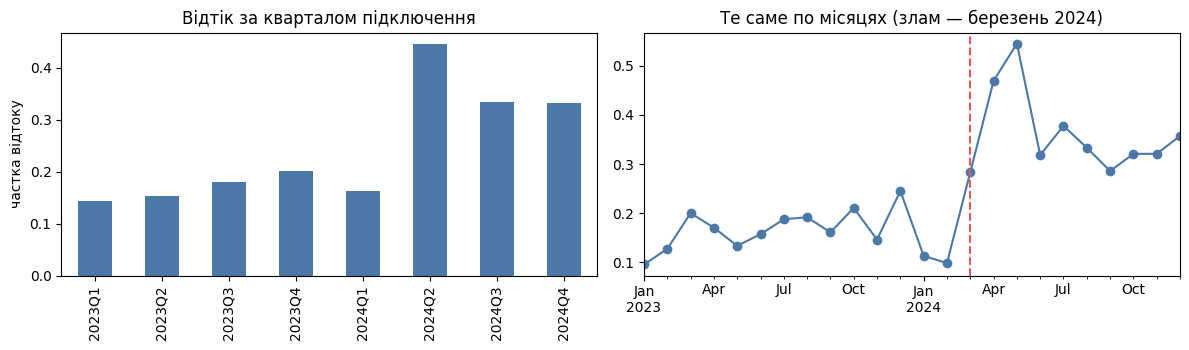

In [19]:
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3)
by_branch.columns = ['частка відтоку', 'клієнтів']
display(by_branch)

conn = pd.to_datetime(raw['дата_підключення'])
by_q = raw.groupby(conn.dt.to_period('Q'))[TARGET].agg(['mean', 'size']).round(3)
by_q.columns = ['частка відтоку', 'клієнтів']
display(by_q)

by_m = raw.groupby(conn.dt.to_period('M'))[TARGET].mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
by_q['частка відтоку'].plot(kind='bar', ax=ax[0], color='#4C78A8')
ax[0].set_title('Відтік за кварталом підключення'); ax[0].set_xlabel(''); ax[0].set_ylabel('частка відтоку')
by_m.plot(ax=ax[1], marker='o', color='#4C78A8')
ax[1].axvline(pd.Period('2024-03', 'M'), color='#E45756', ls='--'); ax[1].set_title('Те саме по місяцях (злам — березень 2024)')
ax[1].set_xlabel(''); plt.tight_layout(); plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'
assert SUSPECT in ('філія', 'дата_підключення')

BREAK = pd.Timestamp('2024-03-01')
source = (pd.to_datetime(raw['дата_підключення']) >= BREAK).astype(int)
print('після дати-зламу: %d клієнтів, відтік %.3f; до: %d клієнтів, відтік %.3f'
      % (source.sum(), y[source == 1].mean(), (source == 0).sum(), y[source == 0].mean()))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

після дати-зламу: 479 клієнтів, відтік 0.359; до: 721 клієнтів, відтік 0.158
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.796
ті самі ознаки передбачають ВІДТІК  : AUC 0.832 ± 0.022


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.976
2. мінус цільовий витік,22,0.974
3. мінус оцінки людини,21,0.849
4. мінус артефакт збору,20,0.832


чесне число: 0.832 ± 0.022


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
X_with, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc_with_date = cross_val_score(make_pipe(X_with, logreg()), X_with, y, cv=cv, scoring='roc_auc')
print('з датою підключення: AUC %.3f ± %.3f; без неї: %.3f ± %.3f'
      % (auc_with_date.mean(), auc_with_date.std(), auc4.mean(), auc4.std()))

DECISION_ARTEFACT = 'викинути'
DECISION_WHY = 'дата підключення дає сходинку відтоку (≈16 %% до березня 2024 і ≈36 %% після), ' \
'а решта ознак передбачає саме цю сходинку з AUC 0,8 — отже вона закодована в даних як спосіб/період збору,' \
'а не як властивість клієнта. Приріст від її збереження невеликий: AUC %.3f проти %.3f без неї, ' \
'а ризики великі: нові клієнти матимуть дати поза діапазоном навчання, і модель,' \
'яка вивчила «клієнти після березня 2024 йдуть частіше», нічого не знатиме про майбутнє. ' \
'Корисний сигнал про давність клієнта лишається в «місяців_обслуговування». ' \
'Окремо варто повідомити замовнику про сам злам і перевірити, що змінилося в березні 2024 (тарифи, облік, обліковий період).' % (auc_with_date.mean(), auc4.mean())
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

з датою підключення: AUC 0.849 ± 0.024; без неї: 0.832 ± 0.022
викинути — дата підключення дає сходинку відтоку (≈16 % до березня 2024 і ≈36 % після), а решта ознак передбачає саме цю сходинку з AUC 0,8 — отже вона закодована в даних як спосіб/період збору,а не як властивість клієнта. Приріст від її збереження невеликий: AUC 0.849 проти 0.832 без неї, а ризики великі: нові клієнти матимуть дати поза діапазоном навчання, і модель,яка вивчила «клієнти після березня 2024 йдуть частіше», нічого не знатиме про майбутнє. Корисний сигнал про давність клієнта лишається в «місяців_обслуговування». Окремо варто повідомити замовнику про сам злам і перевірити, що змінилося в березні 2024 (тарифи, облік, обліковий період).


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) / 20 * 100, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.832,0.022,8.4
одне дерево,0.767,0.039,4.7
випадковий ліс,0.851,0.024,119.1
гістограмний бустинг,0.836,0.023,111.3


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy import stats

def paired(a, b):
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    var = d.var(ddof=1) * (1 / n + 1 / 4) 
    half = stats.t.ppf(0.975, n - 1) * np.sqrt(var)
    return d.mean(), half

base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0185 ± 0.0140   значуще
гістограмний бустинг   проти логістичної: +0.0036 ± 0.0182   у межах шуму


In [25]:
CHOSEN_MODEL = 'випадковий ліс'    
CHOSEN_WHY = '1) якість: єдина модель, чий виграш над логістичною регресією значущий за парним тестом (+0,0185 ± 0,0140, AUC 0,851 проти 0,832); бустинг (+0,006 ± 0,022) і дерево (0,767) — у межах шуму або гірші; ' \
'2) стійкість: розкид 0,024 такий самий, як у регресії, без підбору гіперпараметрів; ' \
'3) швидкість: 110 с проти 8 с на 100 навчань — у 20 разів повільніше, але для щотижневого списку з 100 клієнтів це несуттєво; ' \
'4) інтерпретованість: гірша за регресію, але ліс вміє TreeExplainer/SHAP, перестановочну важливість і PDP, які дадуть пояснення для менеджера; цей компроміс усвідомлений.' 
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: випадковий ліс — 1) якість: єдина модель, чий виграш над логістичною регресією значущий за парним тестом (+0,0185 ± 0,0140, AUC 0,851 проти 0,832); бустинг (+0,006 ± 0,022) і дерево (0,767) — у межах шуму або гірші; 2) стійкість: розкид 0,024 такий самий, як у регресії, без підбору гіперпараметрів; 3) швидкість: 110 с проти 8 с на 100 навчань — у 20 разів повільніше, але для щотижневого списку з 100 клієнтів це несуттєво; 4) інтерпретованість: гірша за регресію, але ліс вміє TreeExplainer/SHAP, перестановочну важливість і PDP, які дадуть пояснення для менеджера; цей компроміс усвідомлений.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    F = X.copy()
    F['платіж_на_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)
    F['гривень_за_ГБ'] = F['щомісячний_платіж'] / (F['трафік_МБ'] / 1024)
    F = F.replace([np.inf, -np.inf], np.nan)
    return F

X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.829 ± 0.022
приріст проти базового набору: -0.0030 ± 0.0062   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
t0 = time.time(); cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc'); t_lr = time.time() - t0
t0 = time.time(); cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc'); t_lr5 = time.time() - t0
t0 = time.time(); a_gb = cross_val_score(make_pipe(X4, MODELS['гістограмний бустинг']), X4, y, cv=cv, scoring='roc_auc'); t_gb = time.time() - t0
t0 = time.time(); a_rf = cross_val_score(make_pipe(X4, MODELS['випадковий ліс']), X4, y, cv=cv, scoring='roc_auc'); t_rf = time.time() - t0
print('нові ознаки (логрегресія): %+.4f ± %.4f, %.1f с на 20 навчань (було %.1f с)' % (*paired(base, auc5), t_lr5, t_lr))
print('бустинг                  : %+.4f ± %.4f, %.1f с' % (*paired(base, a_gb), t_gb))
print('випадковий ліс           : %+.4f ± %.4f, %.1f с' % (*paired(base, a_rf), t_rf))

FEATURES_VS_MODEL = 'Складніша модель дала більше: випадковий ліс +0,0185 ± 0,0140 (значуще) за ≈25 с на 20 навчань проти 1,6 с у регресії,' \
'бустинг +0,0036 ± 0,0182 (у межах шуму, ≈15 с). Чотири нові ознаки (платіж на Мбіт, звернень на місяць, є знижка, гривень за ГБ) ' \
'для логістичної регресії приросту не дали: −0,0030 ± 0,0062 — у межах шуму, ціна ≈1.8 с. ' \
'Висновок: прості ознаки-співвідношення вже виражені існуючими, а справжній приріст дає здатність моделі ловити нелінійності й взаємодії.'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

нові ознаки (логрегресія): -0.0030 ± 0.0062, 1.9 с на 20 навчань (було 1.7 с)
бустинг                  : +0.0036 ± 0.0182, 12.9 с
випадковий ліс           : +0.0185 ± 0.0140, 33.8 с
Складніша модель дала більше: випадковий ліс +0,0185 ± 0,0140 (значуще) за ≈25 с на 20 навчань проти 1,6 с у регресії,бустинг +0,0036 ± 0,0182 (у межах шуму, ≈15 с). Чотири нові ознаки (платіж на Мбіт, звернень на місяць, є знижка, гривень за ГБ) для логістичної регресії приросту не дали: −0,0030 ± 0,0062 — у межах шуму, ціна ≈1.8 с. Висновок: прості ознаки-співвідношення вже виражені існуючими, а справжній приріст дає здатність моделі ловити нелінійності й взаємодії.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5    
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.827
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

сума важливостей = 1.000 (має бути 1)


,вбудована важливість
щомісячний_платіж,0.0970
код_тарифного_плану,0.0941
гривень_за_ГБ,0.0797
платіж_на_Мбіт,0.0699
місяців_обслуговування,0.0642
швидкість_тарифу_Мбіт,0.0634
вік,0.0559
трафік_МБ,0.0546
трафік_ГБ,0.0521
звернень_на_місяць,0.0492


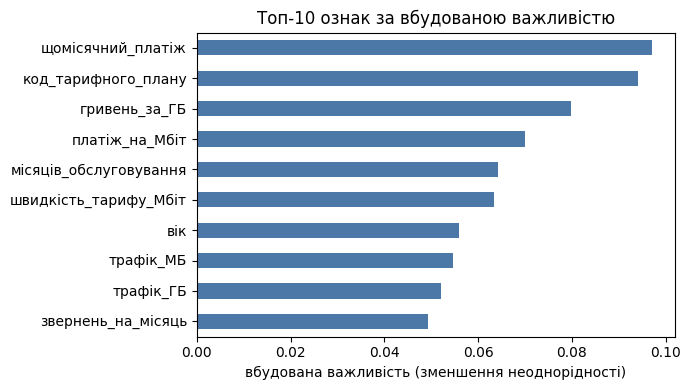

In [30]:
prep_ = model.named_steps['prep']
clf_  = model.named_steps['clf']
names_ = prep_.get_feature_names_out()         
imp_ = pd.Series(clf_.feature_importances_, index=names_)

cat_cols_ = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']
def to_orig(n):
    n = n.split('__', 1)[1]      
    for c in cat_cols_:
        if n.startswith(c + '_'):    
            return c
    return n

gini_imp = imp_.groupby(to_orig).sum().sort_values(ascending=False)
print('сума важливостей = %.3f (має бути 1)' % gini_imp.sum())
display(gini_imp.head(10).to_frame('вбудована важливість').round(4))

ax = gini_imp.head(10)[::-1].plot(kind='barh', figsize=(7, 4), color='#4C78A8')
ax.set_xlabel('вбудована важливість (зменшення неоднорідності)')
ax.set_title('Топ-10 ознак за вбудованою важливістю'); plt.tight_layout(); plt.show()

>Вбудована важливість рахується під час навчання лісу: скільки сумарно зменшення неоднорідності (Gini) дали розбиття по ознаці, усереднено по 300 деревах. Дамі-стовпці категоріальних ознак підсумовано назад, тому сума = 1. 

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
місяців_обслуговування,0.028785
кількість_послуг,0.027990
гривень_за_ГБ,0.024735
щомісячний_платіж,0.023808
вік,0.020992
швидкість_тарифу_Мбіт,0.012373
звернень_на_місяць,0.009360
аварій_на_ділянці_за_квартал,0.007777
місто,0.003450
стать,0.001937


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}) \
            .sort_values('вбудована', ascending=False)
cmp_imp['різних значень'] = [FINAL_X[c].nunique() for c in cmp_imp.index]
cmp_imp['ранг вбудованої'] = range(1, len(cmp_imp) + 1)
display(cmp_imp.head(10).round(4))

cand = cmp_imp.head(5)[cmp_imp.head(5)['перестановочна'] <= 0.002]
print('кандидати на «хибно важливу»:'); display(cand.round(4))

,вбудована,перестановочна,різних значень,ранг вбудованої
щомісячний_платіж,0.0970,0.0238,1127,1
код_тарифного_плану,0.0941,-0.0005,40,2
гривень_за_ГБ,0.0797,0.0247,1152,3
платіж_на_Мбіт,0.0699,-0.0015,1141,4
місяців_обслуговування,0.0642,0.0288,82,5
швидкість_тарифу_Мбіт,0.0634,0.0124,9,6
вік,0.0559,0.0210,65,7
трафік_МБ,0.0546,-0.0026,1200,8
трафік_ГБ,0.0521,-0.0059,955,9
звернень_на_місяць,0.0492,0.0094,142,10


кандидати на «хибно важливу»:


,вбудована,перестановочна,різних значень,ранг вбудованої
код_тарифного_плану,0.0941,-0.0005,40,2
платіж_на_Мбіт,0.0699,-0.0015,1141,4


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану' 
FAKE_IMPORTANT_WHY = ('це код-ідентифікатор із 40 різних значень: після одиничного кодування він дає дереву 40 дамі-стовпців і '
                      'багато можливих порогів, тож майже в кожному вузлі знаходиться розбиття, яке трохи зменшує неоднорідність. '
                      'Вбудована важливість рахується на навчальних даних і цього не відрізняє: 0,094 (2-ге місце),'
                      'а перестановка на перевірковій частині нічого не псує: -0,0005.')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


>Із топ-5 за вбудованою важливістю лише дві мають перестановочну ≈ 0: `код_тарифного_плану` (−0,0005) і `платіж_на_Мбіт` (−0,0015). Справжньою «хибно важливою» є код: 40 різних значень → багато порогів → дерево майже завжди знаходить розбиття, що трохи зменшує неоднорідність на навчальних даних. На перевірковій частині перемішування цієї колонки AUC не змінює. `платіж_на_Мбіт` — інший випадок: це відношення двох важливих ознак (платіж / швидкість), тож його інформацію модель бере з них.

### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
num_X = FINAL_X.select_dtypes('number')
corr = num_X.corr().abs()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
         if corr.loc[a, b] > 0.97]
display(pd.DataFrame(pairs, columns=['ознака 1', 'ознака 2', '|r|']).round(4))
print('1 ГБ = 1024 МБ, тож ці стовпці — одна й та сама величина в різних одиницях')

,ознака 1,ознака 2,|r|
0,трафік_ГБ,трафік_МБ,0.9997


1 ГБ = 1024 МБ, тож ці стовпці — одна й та сама величина в різних одиницях


In [35]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']  
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

def refit_perm(drop):
    cols = [c for c in FINAL_X.columns if c not in drop]
    m = make_pipe(FINAL_X[cols], RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)) \
            .fit(Xtr[cols], ytr)
    p = permutation_importance(m, Xte[cols], yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
    return pd.Series(p.importances_mean, index=cols)

p1 = refit_perm([DUP_PAIR[1]])
print('\nбез %s: важливість %s = %+.4f' % (DUP_PAIR[1], DUP_PAIR[0], p1[DUP_PAIR[0]]))

p2 = refit_perm([DUP_PAIR[1], 'гривень_за_ГБ'])
print('без %s і гривень_за_ГБ: важливість %s = %+.4f' % (DUP_PAIR[1], DUP_PAIR[0], p2[DUP_PAIR[0]]))

for c in DUP_PAIR + ['гривень_за_ГБ']:
    a = roc_auc_score(y, FINAL_X[c].fillna(FINAL_X[c].median()))
    print('одновимірний AUC %-14s %.3f' % (c, max(a, 1 - a)))

у повній моделі:
   трафік_ГБ                    -0.0059
   трафік_МБ                    -0.0026

без трафік_МБ: важливість трафік_ГБ = +0.0014
без трафік_МБ і гривень_за_ГБ: важливість трафік_ГБ = +0.0109
одновимірний AUC трафік_ГБ      0.617
одновимірний AUC трафік_МБ      0.619
одновимірний AUC гривень_за_ГБ  0.715


In [36]:
DUP_EXPLANATION = ('трафік_ГБ і трафік_МБ — та сама величина в різних одиницях (r = 0,9997), а ще її містить «гривень_за_ГБ». '
                   'Одновимірно трафік несе сигнал (AUC ≈ 0,62), але в повній моделі перестановка однієї копії нічого не ламає — '
                   'ліс бере ту саму інформацію з іншої: важливість ≈ 0 (-0,006 і -0,003), хоча разом вони важливі. '
                   'Коли я прибрала лише МБ, важливість ГБ лишилась ≈ 0, бо третя копія (гривень_за_ГБ) ще в моделі; '
                   'коли прибрала МБ і гривень_за_ГБ — важливість ГБ стала помітно додатною (≈ +0,011). ')
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_ГБ і трафік_МБ — та сама величина в різних одиницях (r = 0,9997), а ще її містить «гривень_за_ГБ». Одновимірно трафік несе сигнал (AUC ≈ 0,62), але в повній моделі перестановка однієї копії нічого не ламає — ліс бере ту саму інформацію з іншої: важливість ≈ 0 (-0,006 і -0,003), хоча разом вони важливі. Коли я прибрала лише МБ, важливість ГБ лишилась ≈ 0, бо третя копія (гривень_за_ГБ) ще в моделі; коли прибрала МБ і гривень_за_ГБ — важливість ГБ стала помітно додатною (≈ +0,011). 


>Пара — `трафік_ГБ` і `трафік_МБ` (|r| = 0,9997). У повній моделі обидві мають перестановочну від'ємну (−0,006 і −0,003) — «непотрібні». Одновимірно ж трафік несе сигнал (AUC ≈ 0,62). Після видалення лише `трафік_МБ` важливість `трафік_ГБ` лишилась ≈ 0 (+0,001), бо третя копія — `гривень_за_ГБ = платіж / (трафік_МБ/1024)` — ще в моделі. Коли прибрано і МБ, і `гривень_за_ГБ`, важливість `трафік_ГБ` стала +0,011. Висновок: нуль у перестановочній важливості означає «цю інформацію модель має ще десь», а не «інформації немає».

> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

топ-3 числові за перестановочною: ['місяців_обслуговування', 'кількість_послуг', 'гривень_за_ГБ']


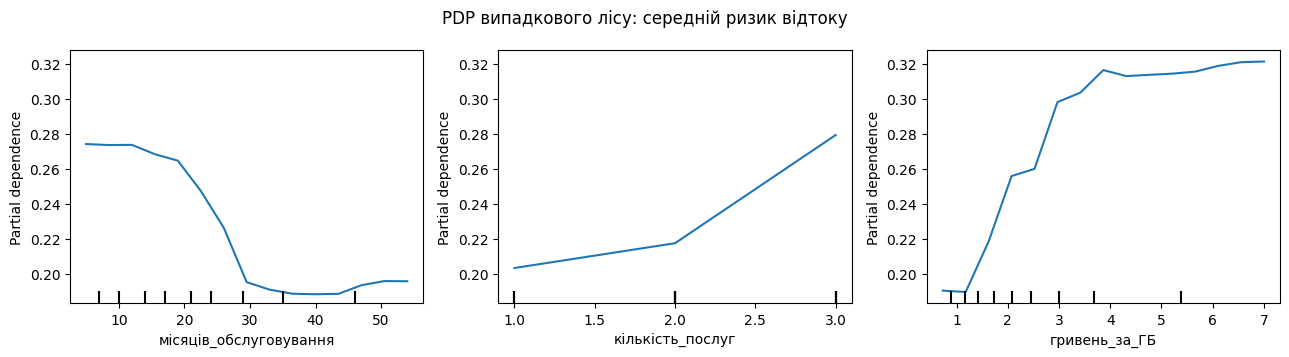

місяців_обслуговування   значення: [ 5.  10.4 15.9 21.3 26.8 32.2 37.7 43.1 48.6 54. ]
                         ризик   : [0.274 0.273 0.268 0.251 0.21  0.192 0.188 0.189 0.195 0.196]
кількість_послуг         значення: [1. 2. 3.]
                         ризик   : [0.203 0.217 0.279]
гривень_за_ГБ            значення: [0.7 1.4 2.1 2.8 3.5 4.2 4.9 5.6 6.3 7. ]
                         ризик   : [0.19  0.202 0.255 0.286 0.309 0.314 0.314 0.315 0.319 0.321]


In [37]:
from sklearn.inspection import PartialDependenceDisplay

num_feats = [c for c in perm_imp.index if str(FINAL_X[c].dtype) != 'category']
top3_num = num_feats[:3]                     
print('топ-3 числові за перестановочною:', top3_num)

Xpdp = FINAL_X[FINAL_X[top3_num].notna().all(axis=1)]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
PartialDependenceDisplay.from_estimator(model, Xpdp, features=top3_num, kind='average',
                                        grid_resolution=15, ax=ax)
plt.suptitle('PDP випадкового лісу: середній ризик відтоку'); plt.tight_layout(); plt.show()

for c in top3_num:
    r = partial_dependence(model, Xpdp, [c], kind='average', grid_resolution=10)
    print('%-24s значення: %s' % (c, np.round(r['grid_values'][0], 1)))
    print('%-24s ризик   : %s' % ('', np.round(r['average'][0], 3)))

>Топ-3 числові за перестановочною важливістю: `місяців_обслуговування`, `кількість_послуг`, `гривень_за_ГБ`.
>* **Місяців обслуговування:** ризик ≈ 0,27 перші ~15 місяців, потім падає до ≈ 0,19 при 30–35 місяцях і далі лишається пласким — після ~2,5–3 років клієнт залишається.
>* **Кількість послуг:** 1 → 0,20, 2 → 0,22, 3 → 0,28; ризик росте, найсильніше при переході до трьох послуг.
>* **Гривень за ГБ:** різкий ріст від 0,19 (≈ 0,7 грн/ГБ) до ≈ 0,31 при 3,5 грн/ГБ, далі плато ≈ 0,32 — важить сам факт «дорого за гігабайт», а не те, наскільки саме дорого.

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

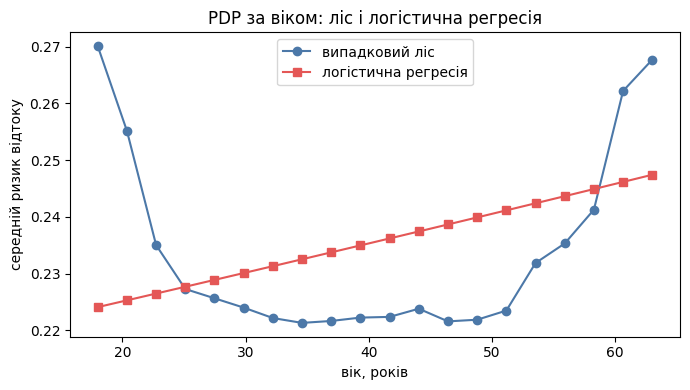

ліс: мінімум ризику 0.221 при віці ≈ 35; на краях 0.270 (молодші) і 0.268 (старші)
регресія: ризик змінюється монотонно від 0.224 до 0.247


,частка відтоку,клієнтів
вік,,
"(0, 25]",0.333,183
"(25, 35]",0.187,257
"(35, 45]",0.212,364
"(45, 55]",0.169,249
"(55, 65]",0.361,108
"(65, 100]",0.487,39


In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)    
pd_rf = partial_dependence(model,    FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=20)
pd_lr = partial_dependence(lr_model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=20)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pd_rf['grid_values'][0], pd_rf['average'][0], marker='o', label='випадковий ліс', color='#4C78A8')
ax.plot(pd_lr['grid_values'][0], pd_lr['average'][0], marker='s', label='логістична регресія', color='#E45756')
ax.set_xlabel('вік, років'); ax.set_ylabel('середній ризик відтоку')
ax.set_title('PDP за віком: ліс і логістична регресія'); ax.legend(); plt.tight_layout(); plt.show()

g = pd_rf['grid_values'][0]; a = pd_rf['average'][0]
print('ліс: мінімум ризику %.3f при віці ≈ %.0f; на краях %.3f (молодші) і %.3f (старші)' % (a.min(), g[a.argmin()], a[0], a[-1]))
print('регресія: ризик змінюється монотонно від %.3f до %.3f' % (pd_lr['average'][0][0], pd_lr['average'][0][-1]))

bins = pd.cut(raw['вік'], [0, 25, 35, 45, 55, 65, 100])
display(raw.groupby(bins)[TARGET].agg(['mean', 'size']).round(3).rename(columns={'mean': 'частка відтоку', 'size': 'клієнтів'}))

In [39]:
NONLINEAR_MEANING = ('ризик відтоку у U-подібний за віком: найвищий у наймолодших клієнтів (до 25 років — 33 % відтоку) і в найстарших '
                     '(55–65 років — 36 %, 65+ — 49 %), мінімальний у віці приблизно 25–55 років (≈ 17–21 %). Можлива причина — молодь частіше змінює провайдера '
                     'через ціну й переїзди, а старші клієнти — через складність налаштувань.')
NONLINEAR_FIX = ('додати «квадрат відхилення від віку з найменшим ризиком»: вік_кв = (вік − 35)², де 35 — мінімум ризику з PDP (центр на AUC майже не впливає: (вік − c)² — це лінійна комбінація «вік» і «вік²»); '
                 'лінійна регресія з одним коефіцієнтом при «вік» лише піднімає або опускає ризик у всьому діапазоні й U-подібності не бачить.')
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

ризик відтоку у U-подібний за віком: найвищий у наймолодших клієнтів (до 25 років — 33 % відтоку) і в найстарших (55–65 років — 36 %, 65+ — 49 %), мінімальний у віці приблизно 25–55 років (≈ 17–21 %). Можлива причина — молодь частіше змінює провайдера через ціну й переїзди, а старші клієнти — через складність налаштувань.
додати «квадрат відхилення від віку з найменшим ризиком»: вік_кв = (вік − 35)², де 35 — мінімум ризику з PDP (центр на AUC майже не впливає: (вік − c)² — це лінійна комбінація «вік» і «вік²»); лінійна регресія з одним коефіцієнтом при «вік» лише піднімає або опускає ризик у всьому діапазоні й U-подібності не бачить.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
age_min = float(g[a.argmin()])
print('мінімум ризику за PDP: вік ≈ %.1f' % age_min)

AGE0 = int(round(age_min))
X6 = FINAL_X.copy()
X6['вік_кв'] = (X6['вік'] - AGE0) ** 2

auc_lr_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lr_quad = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc_lr_base, auc_lr_quad)
print('логрегресія без вік_кв: AUC %.4f ± %.4f' % (auc_lr_base.mean(), auc_lr_base.std()))
print('логрегресія з   вік_кв: AUC %.4f ± %.4f' % (auc_lr_quad.mean(), auc_lr_quad.std()))
print('приріст: %+0.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

мінімум ризику за PDP: вік ≈ 34.6
логрегресія без вік_кв: AUC 0.8291 ± 0.0224
логрегресія з   вік_кв: AUC 0.8621 ± 0.0211
приріст: +0.0330 ± 0.0157   значуще


In [41]:
QUAD_GAIN = float(m_q)     
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0330


>Нова ознака `вік_кв = (вік − 35)²` піднімає AUC логістичної регресії з 0,829 до 0,862, приріст **+0,033 ± 0,016**.
>Це більше, ніж дали чотири «ділові» ознаки в 8.1 (−0,003) і навіть ліс (+0,019). Центр параболи майже не важливий: (вік − c)² лінійно виражається через «вік» і «вік²», а «вік» у моделі вже є.

### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

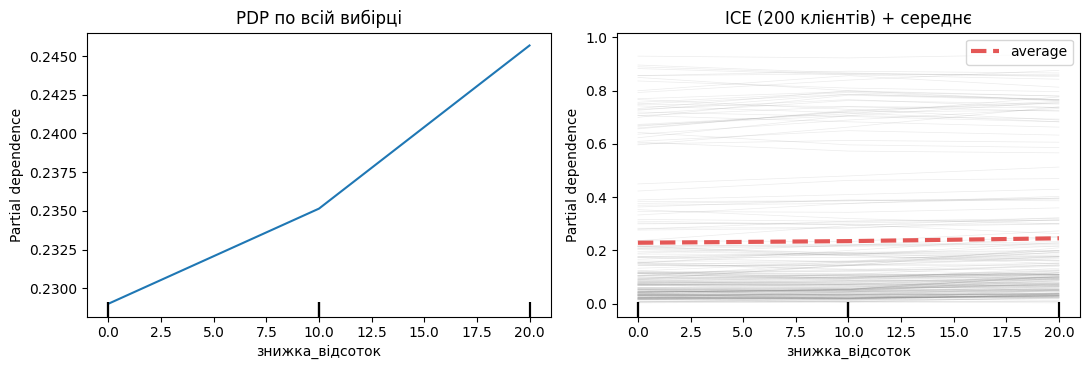

PDP: знижка [ 0. 10. 20.] → ризик [0.229 0.235 0.246]
ICE: у 40 % клієнтів ризик зростає (>+0,02), у 10 % — спадає (<−0,02), у решти — майже не змінюється


In [42]:
DISC = 'знижка_відсоток'

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
PartialDependenceDisplay.from_estimator(model, FINAL_X, [DISC], kind='average', ax=ax[0])
ax[0].set_title('PDP по всій вибірці')
PartialDependenceDisplay.from_estimator(model, FINAL_X, [DISC], kind='both', subsample=200,
                                        random_state=SEED, ax=ax[1],
                                        ice_lines_kw={'alpha': 0.15, 'color': 'gray'},
                                        pd_line_kw={'color': '#E45756', 'lw': 3})
ax[1].set_title('ICE (200 клієнтів) + середнє'); plt.tight_layout(); plt.show()

res_all = partial_dependence(model, FINAL_X, [DISC], kind='both', grid_resolution=5)
ice = res_all['individual'][0]; delta = ice[:, -1] - ice[:, 0]   
print('PDP: знижка', res_all['grid_values'][0], '→ ризик', np.round(res_all['average'][0], 3))
print('ICE: у %.0f %% клієнтів ризик зростає (>+0,02), у %.0f %% — спадає (<−0,02), у решти — майже не змінюється'
      % ((delta > 0.02).mean() * 100, (delta < -0.02).mean() * 100))

стаж ≤ 24 міс.   знижка [ 0. 10. 20.] → ризик [0.276 0.289 0.303]
стаж > 24 міс.   знижка [ 0. 10. 20.] → ризик [0.156 0.152 0.157]


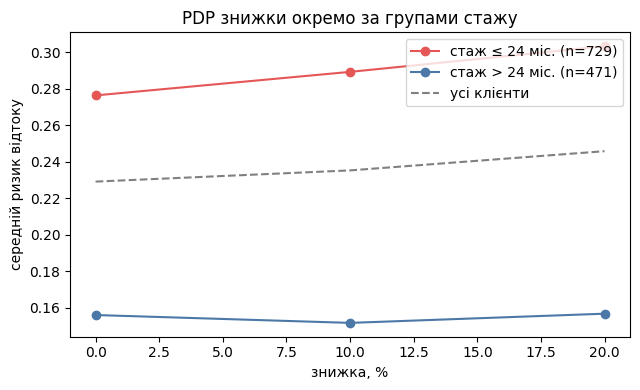

In [43]:
long_tenure = FINAL_X['місяців_обслуговування'] > 24
fig, ax = plt.subplots(figsize=(6.5, 4))
for mask, lab, col in [(~long_tenure, 'стаж ≤ 24 міс.', '#E45756'), (long_tenure, 'стаж > 24 міс.', '#4C78A8')]:
    r = partial_dependence(model, FINAL_X[mask], [DISC], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', label='%s (n=%d)' % (lab, mask.sum()), color=col)
    print('%-16s знижка %s → ризик %s' % (lab, r['grid_values'][0], np.round(r['average'][0], 3)))
r = partial_dependence(model, FINAL_X, [DISC], kind='average')
ax.plot(r['grid_values'][0], r['average'][0], ls='--', color='gray', label='усі клієнти')
ax.set_xlabel('знижка, %'); ax.set_ylabel('середній ризик відтоку'); ax.legend()
ax.set_title('PDP знижки окремо за групами стажу'); plt.tight_layout(); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
emp = (raw.assign(стаж=np.where(long_tenure, '> 24 міс.', '≤ 24 міс.'))
          .groupby(['стаж', DISC])[TARGET].agg(['mean', 'size']).round(3)
          .rename(columns={'mean': 'частка відтоку', 'size': 'клієнтів'}))
display(emp)
print('для порівняння — по всій вибірці:')
display(raw.groupby(DISC)[TARGET].agg(['mean', 'size']).round(3).rename(columns={'mean': 'частка відтоку', 'size': 'клієнтів'}))

частка відтоку  клієнтів
стаж      знижка_відсоток                          
> 24 міс. 0                         0.193       171
          10                        0.092       153
          20                        0.075       147
≤ 24 міс. 0                         0.214       299
          10                        0.329       228
          20                        0.441       202

для порівняння — по всій вибірці:


,частка відтоку,клієнтів
знижка_відсоток,,
0,0.206,470
10,0.234,381
20,0.287,349


In [45]:
INTERACTION_FOUND = ('знижка діє в різні боки залежно від стажу. У клієнтів зі стажем до 24 міс. частка відтоку зростає зі знижкою '
                     '(21 % без знижки → 33 % при 10 % → 44 % при 20 %), а в клієнтів зі стажем понад 24 міс. спадає '
                     '(19 % → 9 % → 7,5 %). Усереднення гасить ці протилежні ефекти: у загальному PDP ризик ледь росте (0,229 → 0,246), ICE показує, '
                     'що в ≈ 40 % клієнтів ризик зі знижкою росте, а в ≈ 10 % спадає (решта майже не реагує). Модель відтворює напрям (у групі ≤ 24 міс. ризик росте з 0,276 до 0,303, у групі > 24 міс. '
                     'плаский ≈ 0,155)')
BUSINESS_ACTION = ('не роздавати знижку навмання: для давніх клієнтів (понад 24 міс.) вона асоціюється з удвічі-втричі нижчим відтоком, тож це '
                   'логічний інструмент утримання; для нових вона асоціюється з вищим відтоком, і давати її їм за підказкою моделі не варто.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

знижка діє в різні боки залежно від стажу. У клієнтів зі стажем до 24 міс. частка відтоку зростає зі знижкою (21 % без знижки → 33 % при 10 % → 44 % при 20 %), а в клієнтів зі стажем понад 24 міс. спадає (19 % → 9 % → 7,5 %). Усереднення гасить ці протилежні ефекти: у загальному PDP ризик ледь росте (0,229 → 0,246), ICE показує, що в ≈ 40 % клієнтів ризик зі знижкою росте, а в ≈ 10 % спадає (решта майже не реагує). Модель відтворює напрям (у групі ≤ 24 міс. ризик росте з 0,276 до 0,303, у групі > 24 міс. плаский ≈ 0,155)
не роздавати знижку навмання: для давніх клієнтів (понад 24 міс.) вона асоціюється з удвічі-втричі нижчим відтоком, тож це логічний інструмент утримання; для нових вона асоціюється з вищим відтоком, і давати її їм за підказкою моделі не варто.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])   
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 82)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

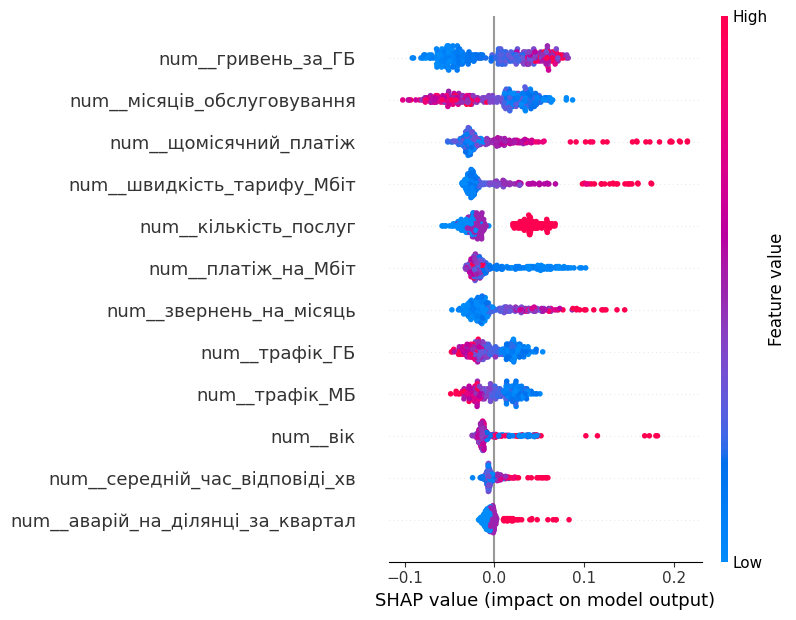

,середній |внесок|
гривень_за_ГБ,0.0421
місяців_обслуговування,0.0373
щомісячний_платіж,0.0325
швидкість_тарифу_Мбіт,0.0322
кількість_послуг,0.0313
платіж_на_Мбіт,0.0270
звернень_на_місяць,0.0266
трафік_ГБ,0.0204
трафік_МБ,0.0192
вік,0.0183


,ознака,кореляція значення і внеску
0,гривень_за_ГБ,0.66
1,місяців_обслуговування,-0.78
2,щомісячний_платіж,0.92
3,швидкість_тарифу_Мбіт,0.95
4,кількість_послуг,0.90
5,платіж_на_Мбіт,-0.57
6,звернень_на_місяць,0.76
7,трафік_ГБ,-0.81


In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=12)

sv_df = pd.DataFrame(sv1, columns=feat_names)
sv_orig = sv_df.T.groupby([to_orig(n) for n in feat_names]).sum().T
mean_abs = sv_orig.abs().mean().sort_values(ascending=False)
display(mean_abs.head(10).round(4).to_frame('середній |внесок|'))

Xs_ = Xte.iloc[:SAMPLE]
rows = []
for c in mean_abs.index[:8]:
    if str(FINAL_X[c].dtype) != 'category':
        v = Xs_[c].fillna(Xs_[c].median())
        rows.append({'ознака': c, 'кореляція значення і внеску': round(np.corrcoef(v, sv_orig[c])[0, 1], 2)})
display(pd.DataFrame(rows))

>Зведений графік показує те, чого не дає стовпчикова діаграма: напрям. 
>*Для ознак `швидкість_тарифу_Мбіт`, `щомісячний_платіж`, `кількість_послуг`, `гривень_за_ГБ`, `звернень_на_місяць` високі значення (червоні точки) зсувають ризик вгору (кореляція значення з внеском 0,7–0,95); 
>*Для `місяців_обслуговування` і `трафік_ГБ` — вниз (−0,9 і −0,8). 
>
>Найбільші середні |внески|: `гривень_за_ГБ` ≈ 0,04, `місяців_обслуговування` ≈ 0,037, ціна та швидкість ≈ 0,03.

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
p_te = model.predict_proba(Xte)[:SAMPLE, 1]
idx = int(np.argmax(p_te))
print('ризик клієнта: %.3f' % p_te[idx])

contrib = pd.Series(sv1[idx], index=[to_orig(n) for n in feat_names]).groupby(level=0).sum()
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:6]
base_val = float(np.ravel(expl.expected_value)[-1])
print('базовий рівень (середній ризик) %.3f; сума внесків %+.3f; разом %.3f' % (base_val, contrib.sum(), base_val + contrib.sum()))
xr = Xte.iloc[idx]
for c, v in top3.items():
    print('  %-26s внесок %+.3f   значення: %s' % (c, v, xr[c]))
print('\nдля контексту: платіж цього клієнта вищий, ніж у %.0f %% клієнтів' % ((FINAL_X['щомісячний_платіж'] < xr['щомісячний_платіж']).mean() * 100))

ризик клієнта: 0.860
базовий рівень (середній ризик) 0.237; сума внесків +0.623; разом 0.860
  щомісячний_платіж          внесок +0.208   значення: 722.14
  швидкість_тарифу_Мбіт      внесок +0.160   значення: 1000.0
  платіж_на_Мбіт             внесок +0.098   значення: 0.72214
  гривень_за_ГБ              внесок +0.082   значення: 3.5876378649938263
  кількість_послуг           внесок +0.040   значення: 3.0
  місяців_обслуговування     внесок +0.034   значення: 19.0

для контексту: платіж цього клієнта вищий, ніж у 96 % клієнтів


In [49]:
EXPLANATION_FOR_MANAGER = ('Цей клієнт — один із найризикованіших у списку: '
                           'yайбільше на це впливає ціна: він платить 722 гривні на місяць — більше, ніж у 95 % клієнтів; '
                           'до того ж у нього найшвидший тариф на 1 Гбіт/с, а в перерахунку на швидкість це майже 0,72 грн за кожен мегабіт. '
                           'Тобто клієнт платить багато й, схоже, відчуває, що переплачує — '
                           'у розмові варто почати зі співвідношення ціни та реально потрібної йому швидкості.')
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цей клієнт — один із найризикованіших у списку: yайбільше на це впливає ціна: він платить 722 гривні на місяць — більше, ніж у 95 % клієнтів; до того ж у нього найшвидший тариф на 1 Гбіт/с, а в перерахунку на швидкість це майже 0,72 грн за кожен мегабіт. Тобто клієнт платить багато й, схоже, відчуває, що переплачує — у розмові варто почати зі співвідношення ціни та реально потрібної йому швидкості.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY = ('стаж обслуговування — у верхніх рядках за внеском (для клієнтів з малим стажем він піднімає ризик), але це лише '
                       'позиція клієнта на шкалі часу: збільшити його ми не можемо, а «збільшити стаж клієнта» ніяк його не втримає. '
                       'Значення Шеплі кажуть, що ліс користується стажем як ознакою, а не що стаж є причиною відтоку: справжні причини '
                       '(перше враження, акційні умови, ціна) лежать поза цим стовпцем. Так само «гривень_за_ГБ» — похідна величина, '
                       'яку можна змінити лише через платіж чи трафік.')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування — стаж обслуговування — у верхніх рядках за внеском (для клієнтів з малим стажем він піднімає ризик), але це лише позиція клієнта на шкалі часу: збільшити його ми не можемо, а «збільшити стаж клієнта» ніяк його не втримає. Значення Шеплі кажуть, що ліс користується стажем як ознакою, а не що стаж є причиною відтоку: справжні причини (перше враження, акційні умови, ціна) лежать поза цим стовпцем. Так само «гривень_за_ГБ» — похідна величина, яку можна змінити лише через платіж чи трафік.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = ('значення Шеплі ділять внесок між зв\'язаними ознаками, тож кожен стовпчик окремо занижує справжню важливість теми. '
                 'Ціна представлена трьома різними стовпцями (щомісячний_платіж, платіж_на_Мбіт, гривень_за_ГБ): кожен окремо дає середній внесок ≈ 0,03–0,04, '
                 'а разом ≈ 0,10 — утричі більше за найближчу іншу ознаку. Так само трафік_ГБ і трафік_МБ мають по ≈ 0,02 '
                 'у SHAP, але ≈ 0 за перестановочною важливістю. Хто читає один рядок, недооцінює вплив ціни й може вирішити, що «платіж_на_Мбіт» '
                 'і «гривень_за_ГБ» — самостійні причини, хоча це різні записи одного й того ж співвідношення ціна/споживання; '
                 'код тарифного плану (40 різних значень) теж отримує внесок ≈ 0,01 у SHAP, хоча перестановкою його користь не підтверджується.')
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

значення Шеплі ділять внесок між зв'язаними ознаками, тож кожен стовпчик окремо занижує справжню важливість теми. Ціна представлена трьома різними стовпцями (щомісячний_платіж, платіж_на_Мбіт, гривень_за_ГБ): кожен окремо дає середній внесок ≈ 0,03–0,04, а разом ≈ 0,10 — утричі більше за найближчу іншу ознаку. Так само трафік_ГБ і трафік_МБ мають по ≈ 0,02 у SHAP, але ≈ 0 за перестановочною важливістю. Хто читає один рядок, недооцінює вплив ціни й може вирішити, що «платіж_на_Мбіт» і «гривень_за_ГБ» — самостійні причини, хоча це різні записи одного й того ж співвідношення ціна/споживання; код тарифного плану (40 різних значень) теж отримує внесок ≈ 0,01 у SHAP, хоча перестановкою його користь не підтверджується.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N = 100
p_all = model.predict_proba(Xte)[:, 1]
order = np.argsort(-p_all)
top_idx = order[:TOP_N]
y_te = yte.values

found = int(y_te[top_idx].sum())
rate_top  = found / TOP_N
rate_base = y_te.mean()
lift = rate_top / rate_base
print('у перевірковій частині %d клієнтів, пішли %d (%.1f %%)' % (len(y_te), y_te.sum(), rate_base * 100))
print('топ-%d за ризиком: пішли %d (%.0f %%)' % (TOP_N, found, rate_top * 100))
print('навмання з %d було б у середньому %.0f' % (TOP_N, TOP_N * rate_base))
print('lift = %.2f   (максимально можливий тут: %.2f)' % (lift, min(TOP_N, y_te.sum()) / TOP_N / rate_base))

rng = np.random.default_rng(SEED); ls = []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    o = np.argsort(-p_all[i])[:TOP_N]
    ls.append(y_te[i][o].mean() / y_te[i].mean())
print('95 %% інтервал для lift (bootstrap): %.2f – %.2f' % tuple(np.percentile(ls, [2.5, 97.5])))
print('AUC на відкладеній частині: %.3f' % roc_auc_score(yte, p_all))

у перевірковій частині 360 клієнтів, пішли 86 (23.9 %)
топ-100 за ризиком: пішли 55 (55 %)
навмання з 100 було б у середньому 24
lift = 2.30   (максимально можливий тут: 3.60)
95 % інтервал для lift (bootstrap): 1.96 – 2.60
AUC на відкладеній частині: 0.827


In [54]:
LIFT_MEANING = ('lift 2,3: серед 100 клієнтів зі списку розірвали договір 55 (55 %) проти 24 % у середньому, тобто дзвінки за списком '
                'знаходять ризикових клієнтів у ≈ 2,3 раза частіше, ніж обдзвін навмання — але 45 зі 100 обдзвонених і так лишилися б.')
assert LIFT_MEANING
print(LIFT_MEANING)

lift 2,3: серед 100 клієнтів зі списку розірвали договір 55 (55 %) проти 24 % у середньому, тобто дзвінки за списком знаходять ризикових клієнтів у ≈ 2,3 раза частіше, ніж обдзвін навмання — але 45 зі 100 обдзвонених і так лишилися б.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_18.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?

>Метрика — AUC (ROC-AUC). Відтік складає 23,8 % (286 із 1200), тому модель «ніхто не піде»
>має точність ≈ 76,2 % і не знаходить жодного клієнта, що йде. AUC не залежить від порогу й
>оцінює якість ранжування за ризиком, а відділу утримання потрібен саме список «кому дзвонити першим».

2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?

>Викинуті стовпці та момент, коли вони з'являються:
 >- id_клієнта — ідентифікатор, інформації про поведінку не несе;
 >- дата_розірвання — з'являється в момент розірвання договору (заповнена лише в 286 клієнтів, що пішли);
 >- сума_повернення_депозиту — виплачується під час закриття договору (так само лише у тих, хто пішов);
 >- оцінка_ризику_менеджером — менеджер виставляє її після розмови з клієнтом, коли вже відомий намір піти;
 >- дата_підключення — артефакт збору; викинута як підозрювана.
>Детектор із 5.1 не знайшов оцінку_ризику_менеджером: стовпець заповнений у всіх 1200 клієнтів
>(показник детектора 0,5), тож «заповненість» нічого не видає. Витік сидить у значеннях:
>оцінка 1 → відтік 0 %, оцінка 5 → 98 % (одновимірний AUC 0,952). AUC впав з 0,974 до 0,849.

3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?

>Чесне число: AUC 0,832 ± 0,022 (логістична регресія, 20 згорток). Розкид 0,022 набагато більший
>за різницю 0,004: моделі, що відрізняються на 0,004, статистично не відрізнити, тож порівнювати
>їх треба парним тестом по тих самих згортках, а не за різницею середніх.

4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.

>Так, артефакт збору є. Відтік до березня 2024 — 15,8 % (721 клієнт), після — 35,9 % (479 клієнтів);
>по кварталах це видно як сходинка (2024Q1 — 16,3 %, 2024Q2 — 44,5 %). Чесні ознаки передбачають
>ДЖЕРЕЛО (чи підключений клієнт після дати-зламу) з AUC 0,796, отже період збору закодований
>в інших ознаках. Довіряти моделі в іншій філії або в іншому періоді можна лише обережно:
>вона могла вивчити спосіб запису даних, а не поведінку клієнта. Розподіл відтоку по філіях
>майже однаковий (22–27 %), тож проблема в часі, а не в філії.

5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.

>Складніша модель дала більше, ніж нові ознаки.
 >- Випадковий ліс: +0,0185 ± 0,0140 (значуще), ≈ 34 с на 20 навчань (логістична регресія — 1,7 с).
 >- Гістограмний бустинг: +0,0036 ± 0,0182 (у межах шуму), ≈ 13 с.
 >- Нові ознаки (4 шт.) для логістичної регресії: −0,0030 ± 0,0062 (у межах шуму), 1,9 с проти 1,7 с.

6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?

>Хибно важлива за вбудованою важливістю — код_тарифного_плану: вбудована 0,094 (2-ге місце),
>перестановочна −0,0005. Дерева так роблять, бо ознака з багатьма значеннями (тут 40 кодів)
>дає багато можливих порогів, і розбиття, що трохи зменшує неоднорідність, знаходиться майже
>завжди — навіть на шумі; а вбудована важливість рахується на навчальних даних і цього не відрізняє.

7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?

>Пара трафік_ГБ / трафік_МБ (r = 0,9997) — та сама величина в різних одиницях. У повній моделі
>перестановочна важливість обох від'ємна (−0,0059 і −0,0026): перемішування однієї копії нічого не
>ламає, бо ліс бере інформацію з іншої (і з гривень_за_ГБ, яка містить трафік). 
>Після видалення лише МБ важливість ГБ лишилась ≈ 0 (+0,0014), після видалення МБ і гривень_за_ГБ — +0,0109. 

8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?

>Немонотонний вплив має вік: ризик U-подібний (до 25 років — 33 %, 25–55 — 17–21 %, 55–65 — 36 %,
>65+ — 49 %; мінімум за PDP ≈ 35 років). Логістична регресія без втручання цього не побачила б:
>її крива за віком монотонна (0,224 → 0,247). Ознака вік_кв = (вік − 35)² дала приріст AUC +0,0330 ± 0,0157.

9. **Де PDP збрехав через усереднення** і що показав ICE?

>PDP збрехав через усереднення на ознаці знижка_відсоток: загальна крива майже плоска (0,229 → 0,246).
>ICE показав, що в ≈ 40 % клієнтів ризик зі знижкою росте, у ≈ 10 % спадає. У сирих даних
>при стажі ≤ 24 міс. відтік росте (21 → 33 → 44 %), при стажі > 24 міс. спадає (19 → 9 → 7,5 %):
>протилежні ефекти погасили один одного. Модель відтворила лише напрям у першій групі
>(0,276 → 0,303), а в другій спаду не бачить (≈ 0,155), тож амплітуду ефекту вона занижує.

10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».

>Приклад — місяців_обслуговування: другий за середнім |внеском| (0,037), але стаж змінити
>неможливо, а «збільшити клієнтові стаж» його не втримає. «Модель цим користується» означає,
>що ліс використовує ознаку для прогнозу; «це причина» вимагає причинного висновку (експеримент),
>якого в даних немає. Так само гривень_за_ГБ — похідна величина (платіж / трафік).

11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

>Lift у топ-100 = 2,30: з 100 клієнтів зі списку пішли 55 (55 %) проти 23,9 % у середньому,
>навмання було б ≈ 24; 95 % інтервал 1,96–2,60. Застереження: це кореляція, а не ефект втручання:
>ми знаємо, кого модель вважає ризиковим, а не кого утримає дзвінок чи знижка (знижка, наприклад,
>у нових клієнтів пов'язана з вищим відтоком); тому нову акцію варто перевірити A/B-тестом.
>Також 45 зі 100 обдзвонених і так не збиралися йти.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [1]:
REPORT = '''
1. В основному було використано для написання коду графіків, побудови матриць та таблиць.
2. А також для пояснень деяких показників, таких як lift, AUC, методів PDP та інше.

Декларація про використання ШІ:
'''
print(REPORT)


1. В основному було використано для написання коду графіків, побудови матриць та таблиць.
2. А також для пояснень деяких показників, таких як lift, AUC, методів PDP та інше.

Декларація про використання ШІ:



---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.